In [1]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt

In [12]:
base = "/Users/PITLab/3D_sensors/Processed_data/"
filenames = [
    # f"{base}proc_F_AC100W40_strip3mm_bv103_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv105_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv108_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv110_mcp4400_trigCh4_Ch8_Ru106_low_threshold_retaken.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv105_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",

    # f"{base}proc_F_AC100W40_strip3mm_bv110_mcp4400_trigCh4_Ch8_Ru106_4days.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv116_mcp4400_trigCh4_Ch8_Ru106_2days.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv120_mcp4400_trigCh4_Ch8_Ru106_3days.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv125_mcp4400_trigCh4_Ch8_Ru106_2days.root",
    # f"{base}proc_F_AC100W40_strip3mm_bv113_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",

    # f"{base}proc_F_AC100W40_strip3mm_bv105_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    # f"{base}proc_F_AC100W80_strip3mm_bv105_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",

    # f"{base}proc_F_AC100W80_strip3mm_bv105_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    # f"{base}proc_F_AC100W80_strip3mm_bv110_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    # f"{base}proc_F_AC100W80_strip3mm_bv113_mcp4400_trigCh4_Ch8_Ru106_low_threshold.root",
    f"{base}proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root",
    # f"{base}proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_low_threshold.root",
    f"{base}proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root",    
]

legend_labels = []

for f in filenames:
    bias_voltage = f.split("_bv")[1].split("_")[0] + "V"
    wafer = f.split(f"{base}proc_F_")[1].split("_strip")[0]
    tag = f.split(f"{base}proc_F_")[1].split("_")[-2]
    legend_labels.append(wafer+" "+bias_voltage+" "+tag)
print(legend_labels)
#     "105V (40 um)", "105V (80 um)", # "110 V", "110 V new", # "108 V", "110 V", "113 V", "116 V", "120 V", "125 V"
# ]

['AC100W80 116V Sr90', 'AC100W80 116V high']


[True, True, True, True, True, True, ..., True, True, True, True, True, True]
[True, True, True, True, True, True, ..., True, True, True, True, True, True]


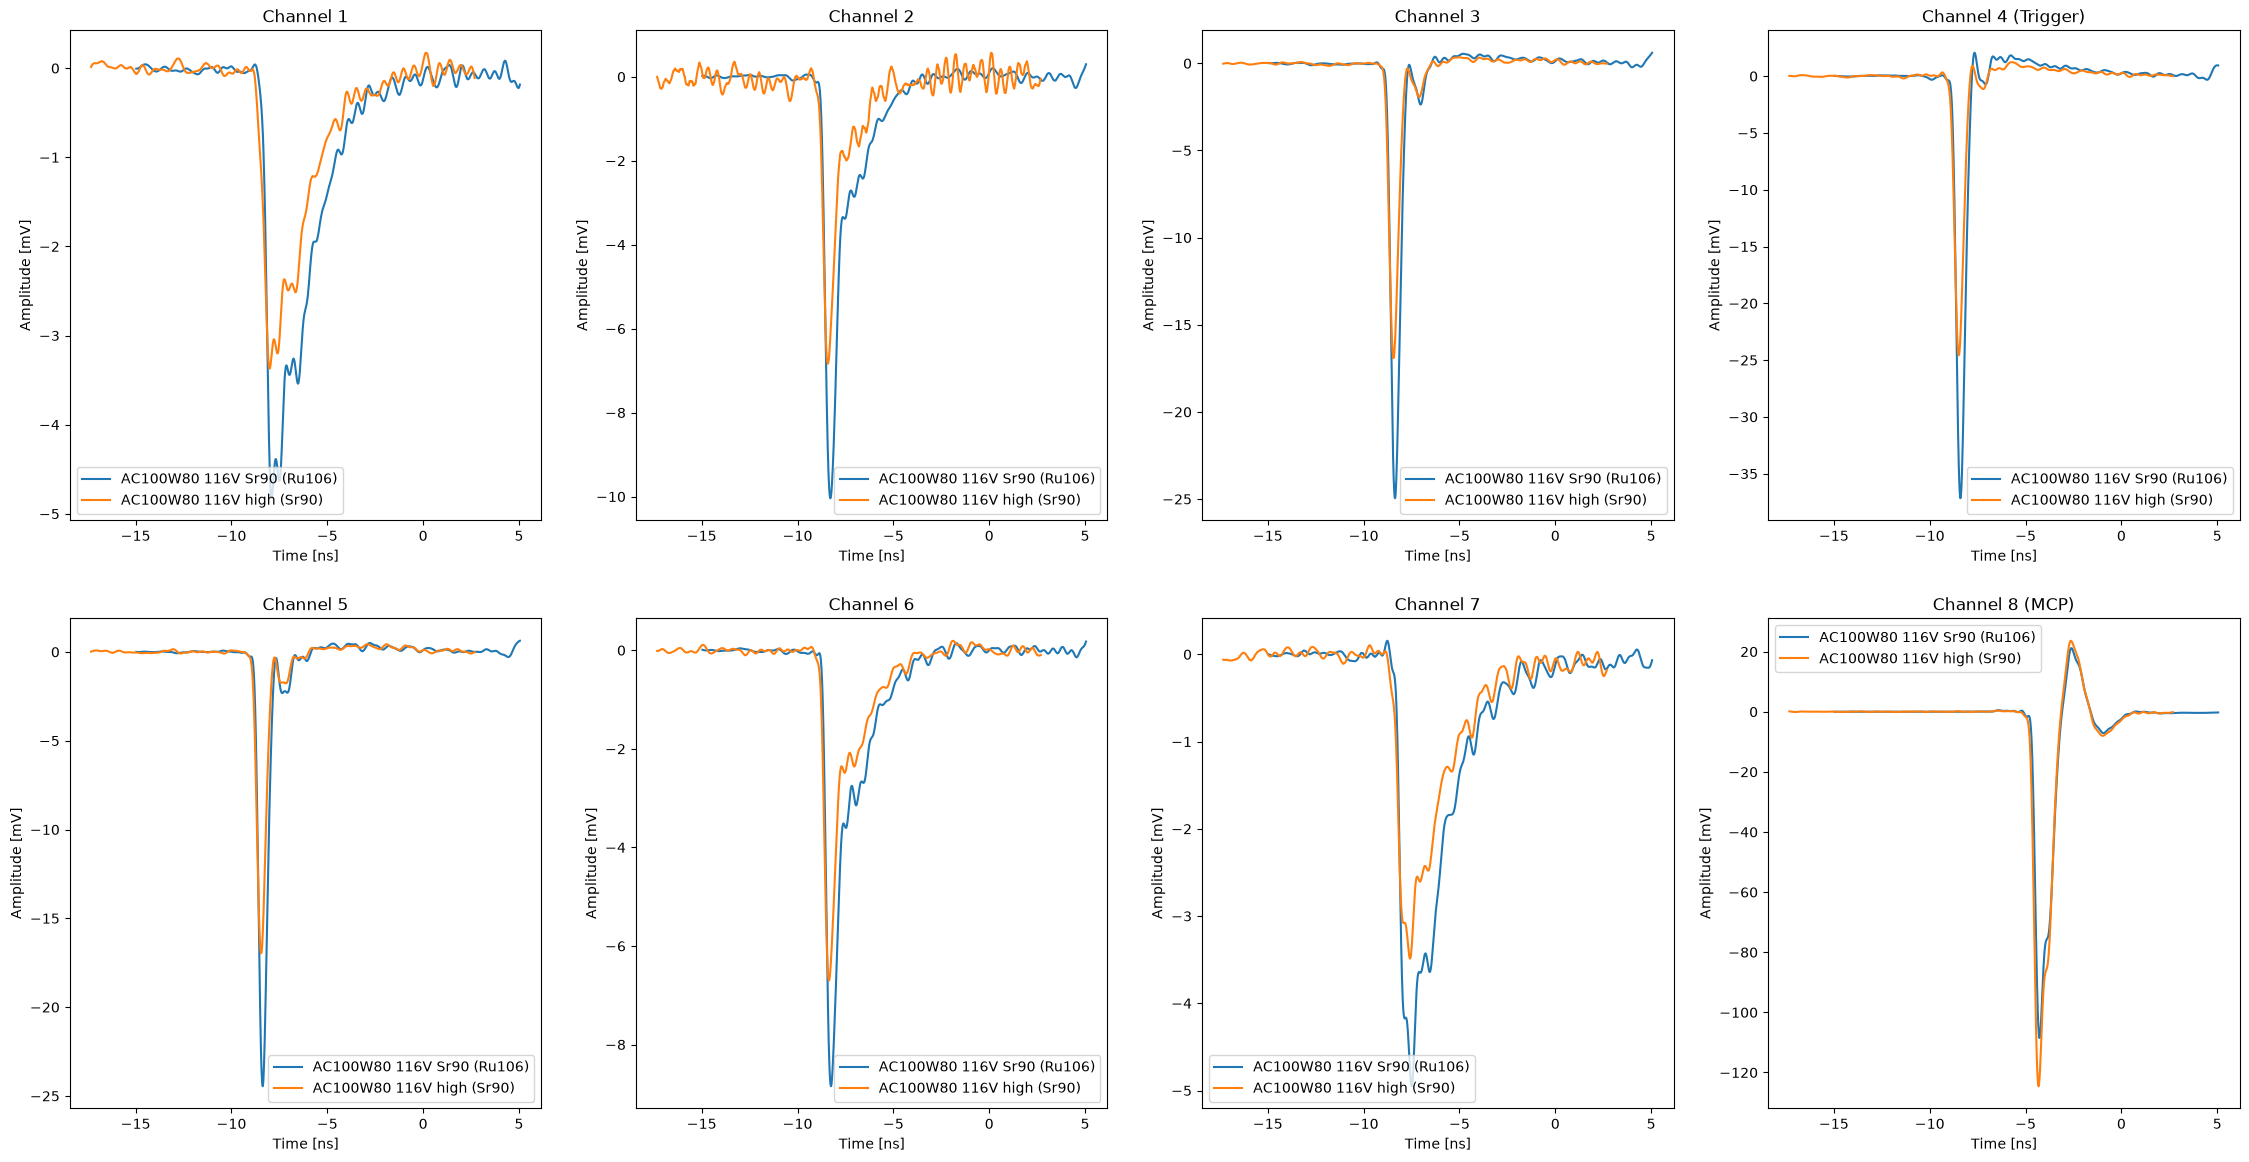

In [13]:
rows = 2
cols = 4
size = 7
fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

for f, file in enumerate(filenames):
    arrays = uproot.open(file)["pulse"].arrays()
    channels = arrays["channel"]
    time = arrays["time"][:,0][0]
    baseline_RMS = arrays["baseline_RMS"]
    amp = arrays["amp"]
    timestamps_10 = arrays["LP2_10"]
    timestamps_80 = arrays["LP2_80"]
    
    sel = (baseline_RMS[:,3] < 3) & ((timestamps_10[:,3] > -13) & (timestamps_10[:,3] > -13) & (timestamps_10[:,3] < -1) & (timestamps_10[:,3] < -1)) #  & (amp[3])
    print(sel)
    mean_channels = ak.mean(channels[sel], axis = 0)
    labels = [
        "Channel 1",
        "Channel 2",
        "Channel 3",
        "Channel 4 (Trigger)",
        "Channel 5",
        "Channel 6",
        "Channel 7",
        "Channel 8 (MCP)"
    ]
    for i, ch in enumerate(mean_channels):
        y = (i) % cols
        x = (i) // cols
        # print(x, y)
        if f == 0:
            ax[x][y].plot(time, ch, label = legend_labels[f]+" (Ru106)")
        else:
            ax[x][y].plot(time, ch, label = legend_labels[f]+" (Sr90)")
        ax[x][y].set_title(labels[i])
        ax[x][y].set_xlabel("Time [ns]")
        ax[x][y].set_ylabel("Amplitude [mV]")
        ax[x][y].legend()

[True, True, True, True, True, True, ..., True, True, True, True, True, True]
[True, True, True, True, True, True, ..., True, True, True, True, True, True]


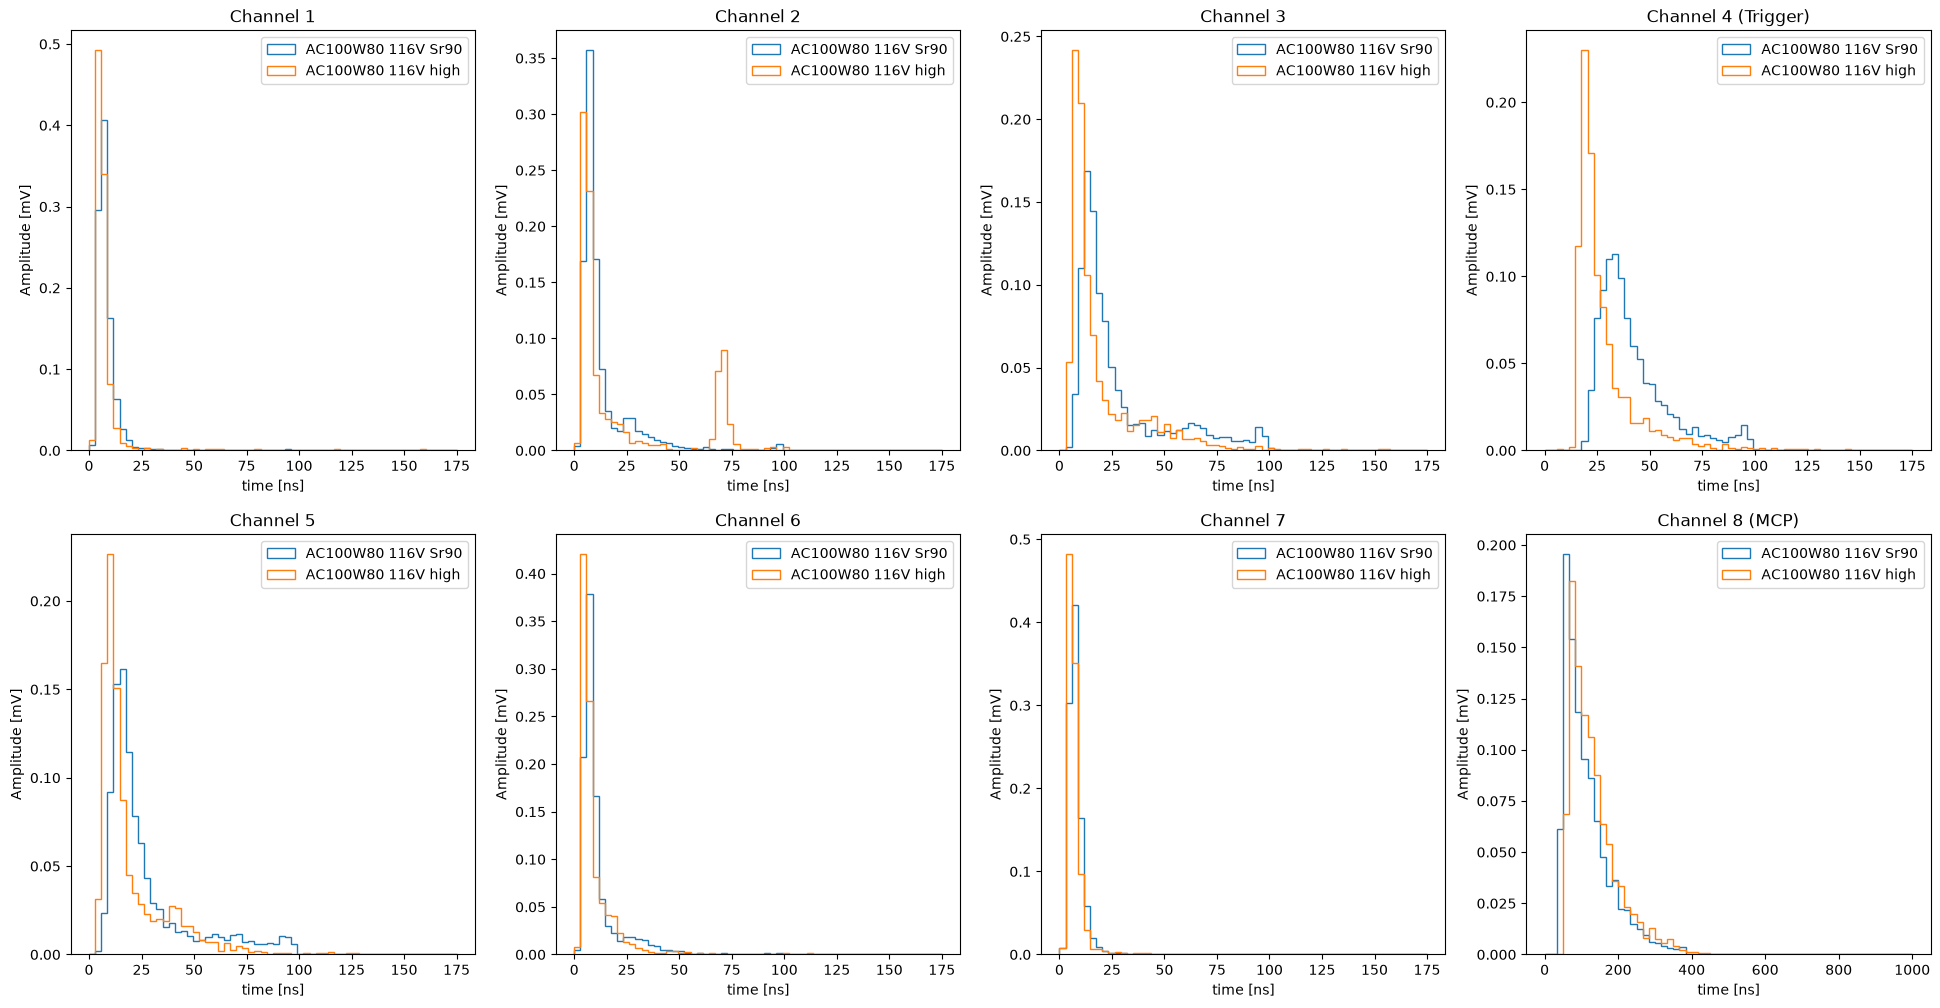

In [30]:
rows = 2
cols = 4
size = 6
fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))

for f, file in enumerate(filenames):
    arrays = uproot.open(file)["pulse"].arrays()

    baseline_RMS = arrays["baseline_RMS"]
    amp = arrays["amp"]
    timestamps_10 = arrays["LP2_10"]
    timestamps_80 = arrays["LP2_80"]
    
    print(sel)
    amps = arrays["amp"]
    for i, ch in enumerate(mean_channels):
        sel = (baseline_RMS[:,i] < 3) #  & ((timestamps_10[:,i] > -13) & (timestamps_10[:,i] > -13) & (timestamps_10[:,i] < -1) & (timestamps_10[:,i] < -1))
        y = (i) % cols
        x = (i) // cols
        # print(x, y)
        if (i == 7):
            x_range = (0, 1000)
        else:
            x_range = (0, 175)
        ax[x][y].hist(amps[:,i][sel], label = legend_labels[f], range=x_range, bins=60, histtype="step", weights=[1.0/len(amps[sel])]*len(amps[sel]))
        # ax[x][y].set_xscale("log")
        # ax[x][y].set_yscale("log")
        ax[x][y].set_title(labels[i])
        ax[x][y].set_xlabel("time [ns]")
        ax[x][y].set_ylabel("Amplitude [mV]")
        ax[x][y].legend()

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root


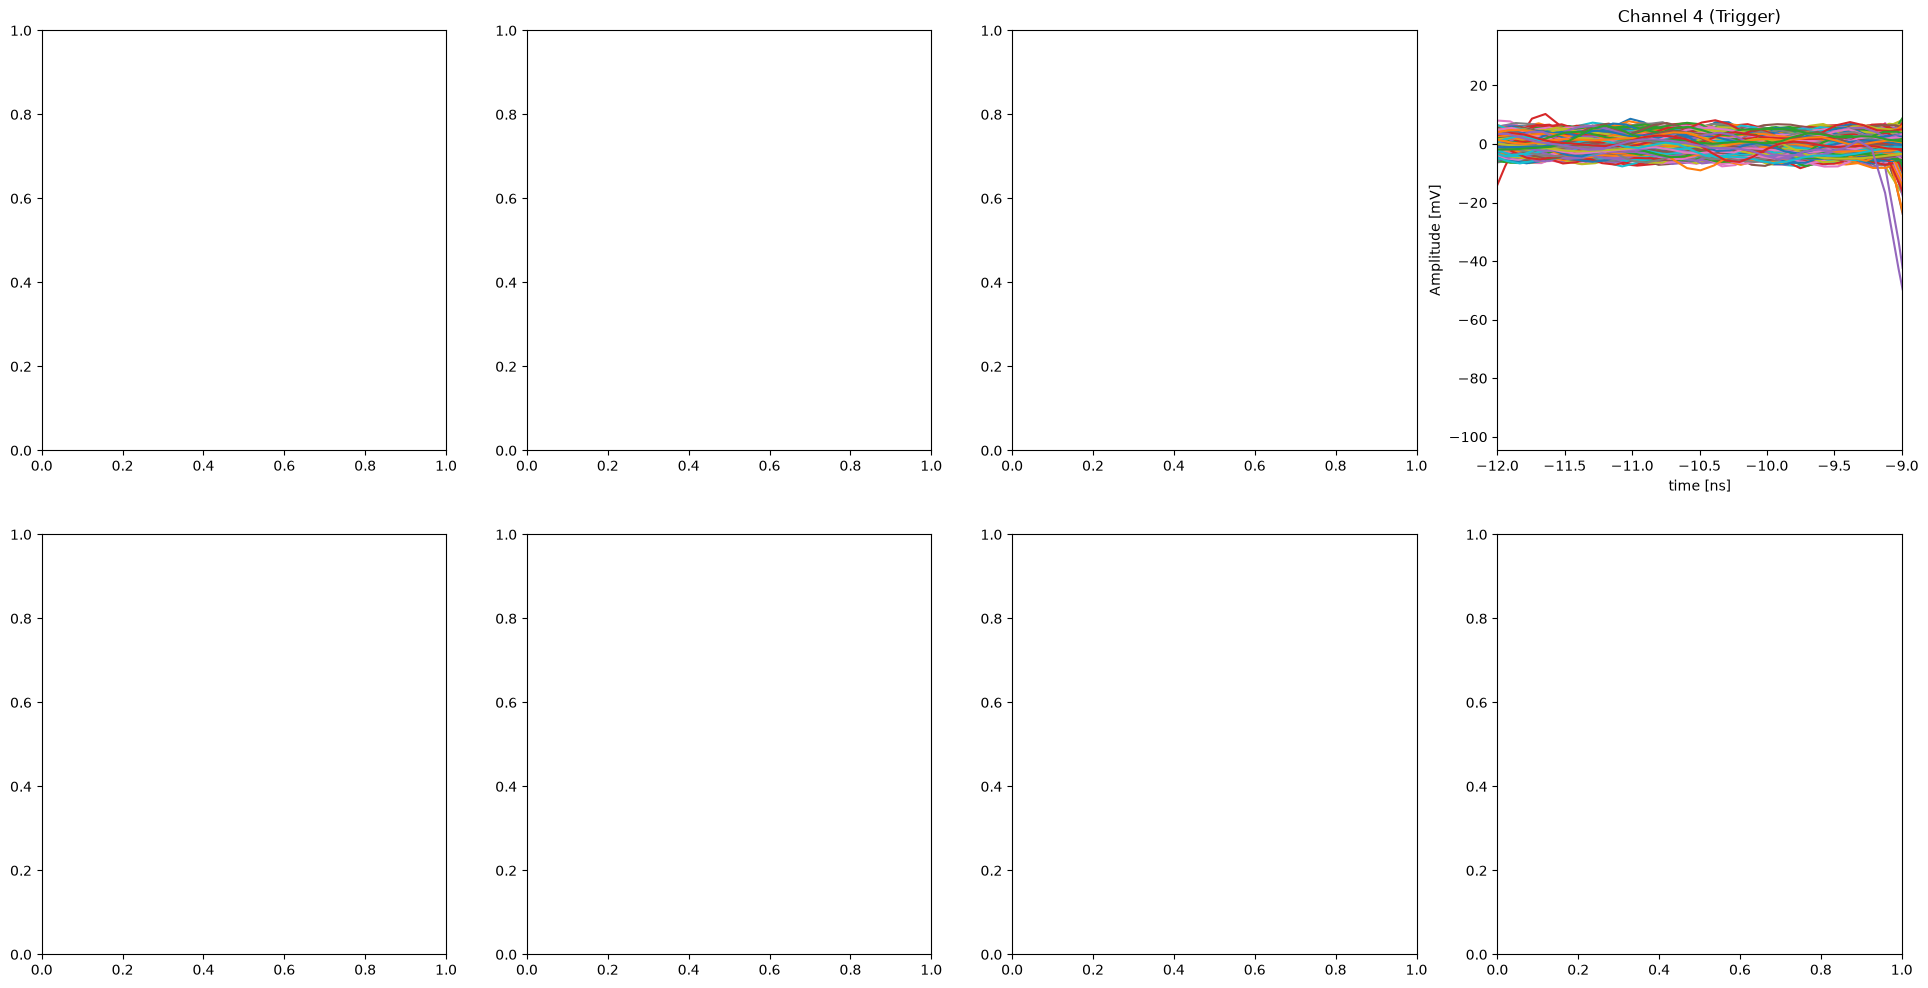

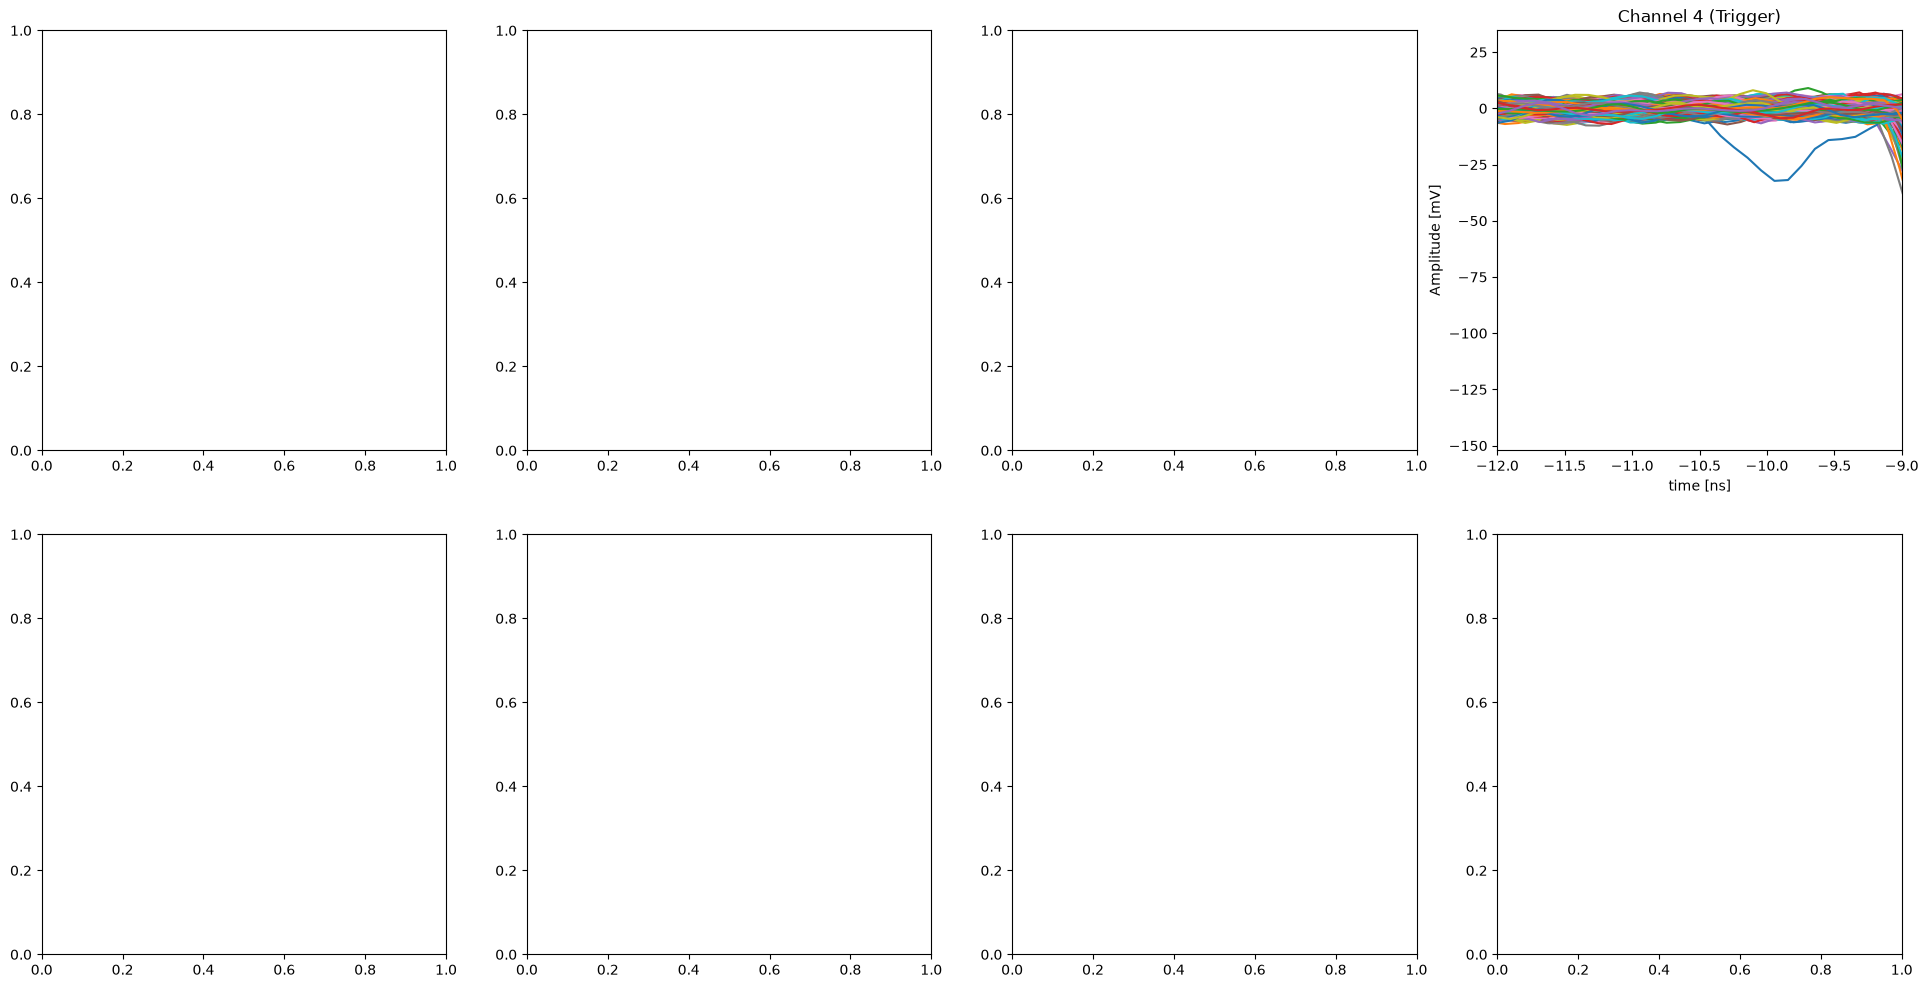

In [15]:
for f, file in enumerate(filenames):
    print(file)
    rows = 2
    cols = 4
    size = 6
    fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))
    arrays = uproot.open(file)["pulse"].arrays()
    channels = arrays["channel"]
    time = arrays["time"]
    baseline_RMS = arrays["baseline_RMS"]
    for i, ch in enumerate(channels[0]):
        y = (i) % cols
        x = (i) // cols
        for e in range(len(channels)):
            # print(channels[e][i])
            if i != 3: continue;
            if baseline_RMS[e][i] > 3: continue;
            ax[x][y].plot(time[i][0], channels[e][i])
            ax[x][y].set_xlim(-12, -9)
            ax[x][y].set_title(labels[i])
            ax[x][y].set_xlabel("time [ns]")
            ax[x][y].set_ylabel("Amplitude [mV]")

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


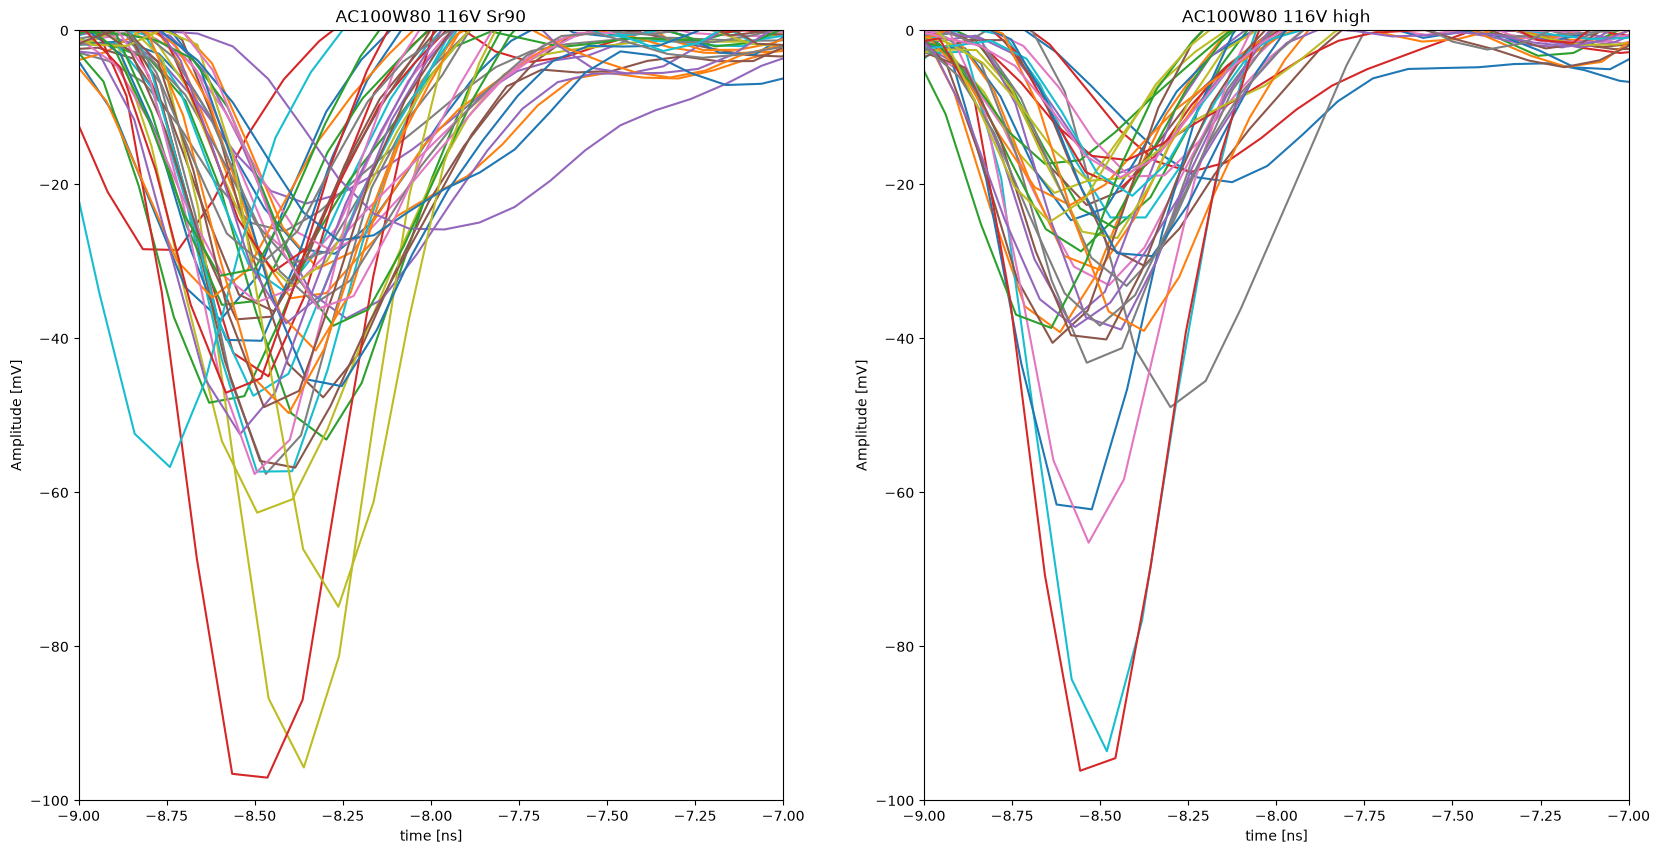

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


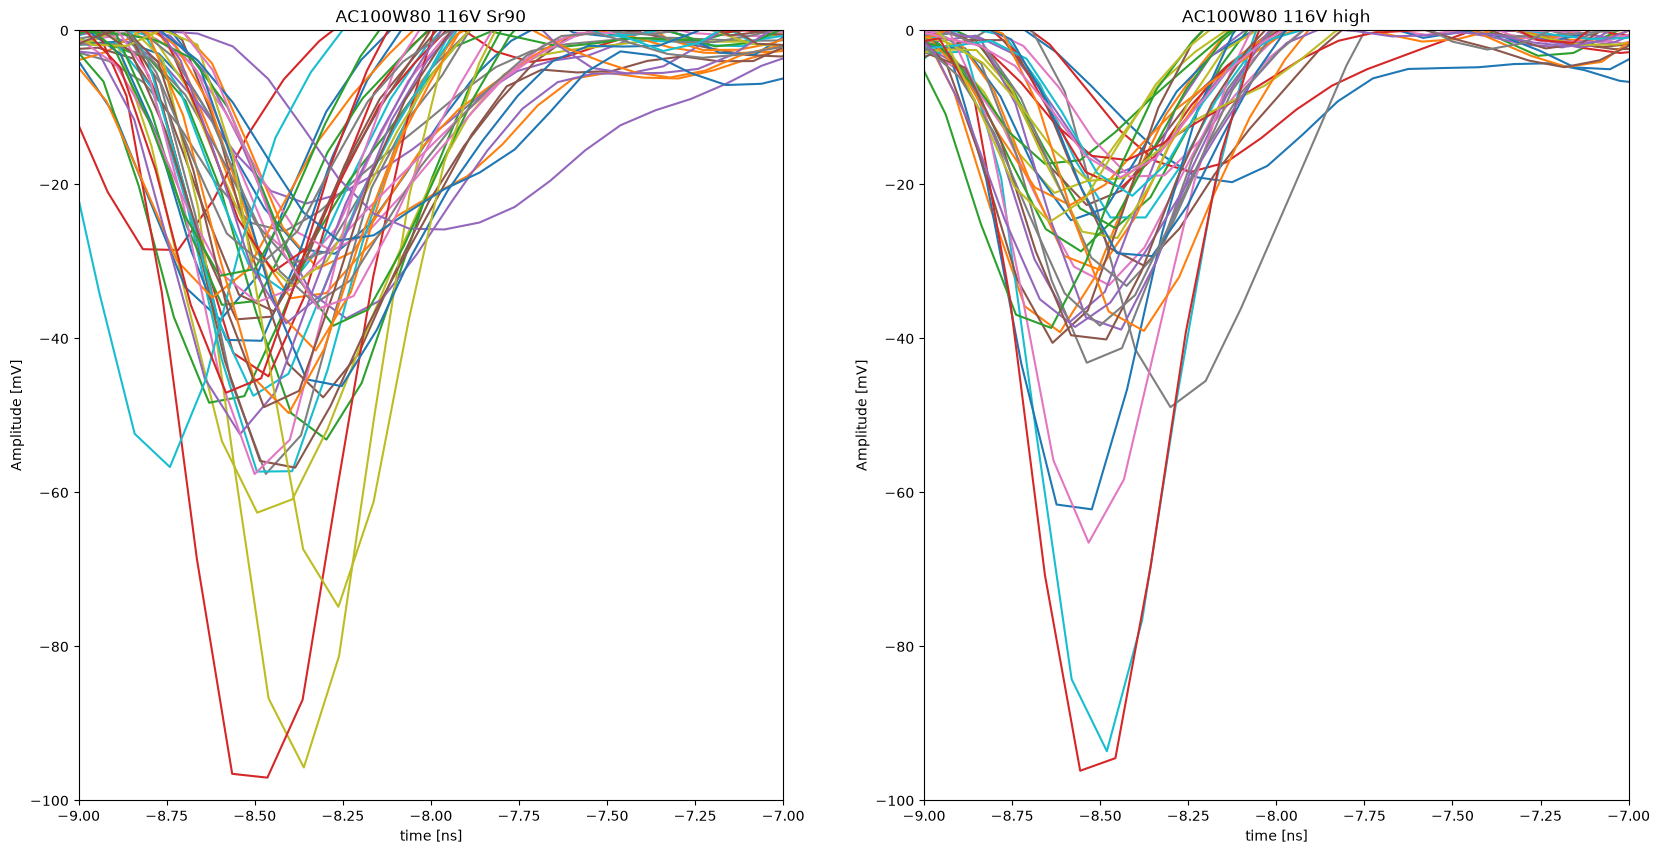

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


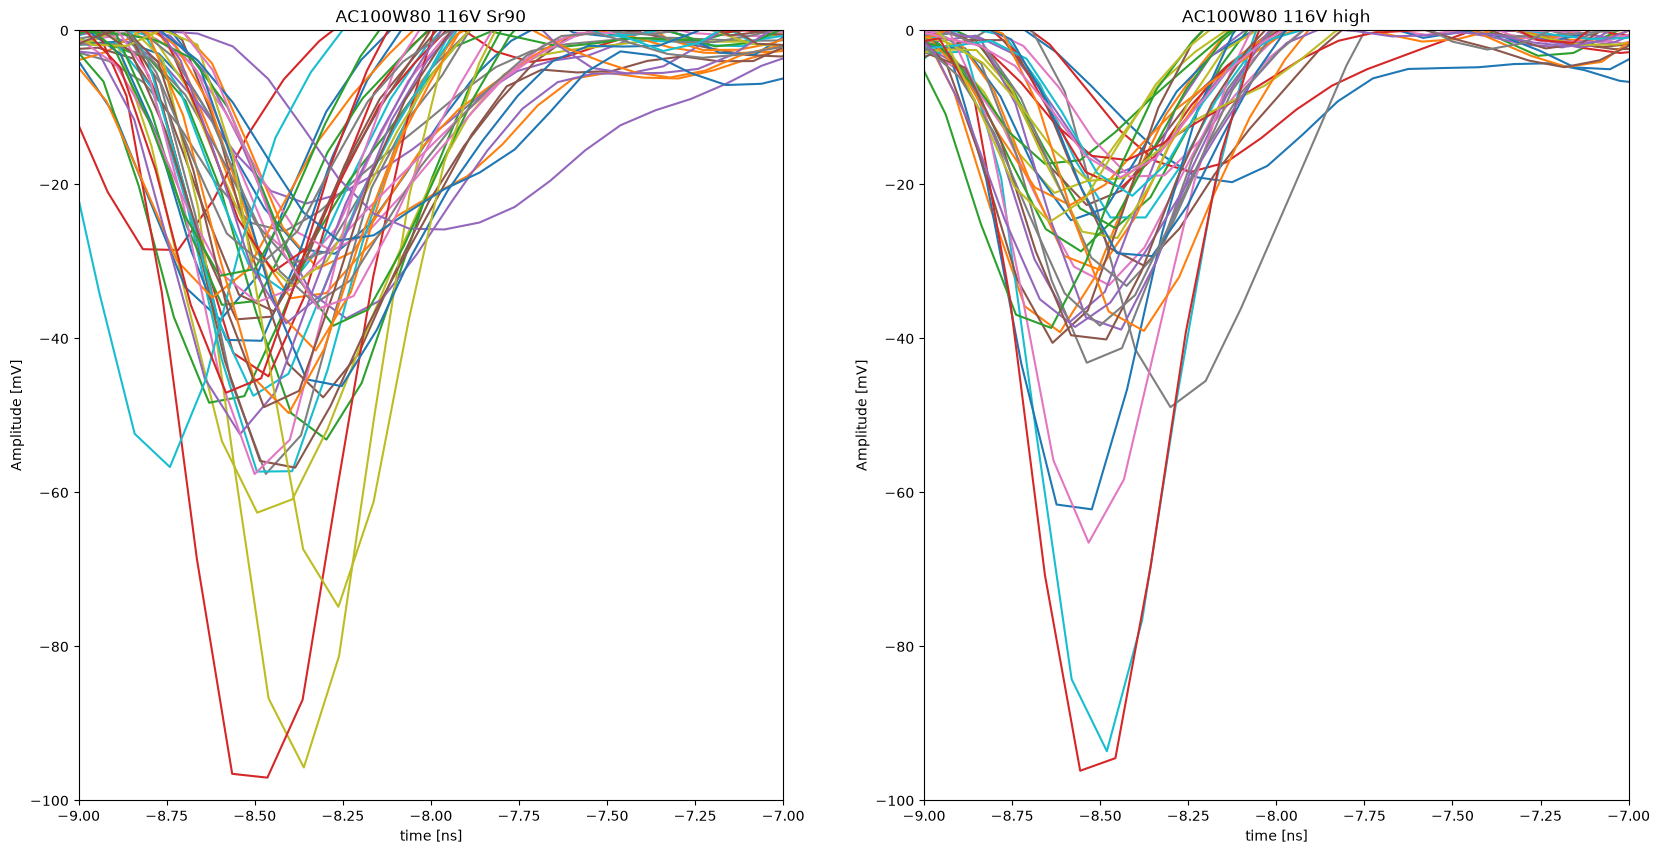

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


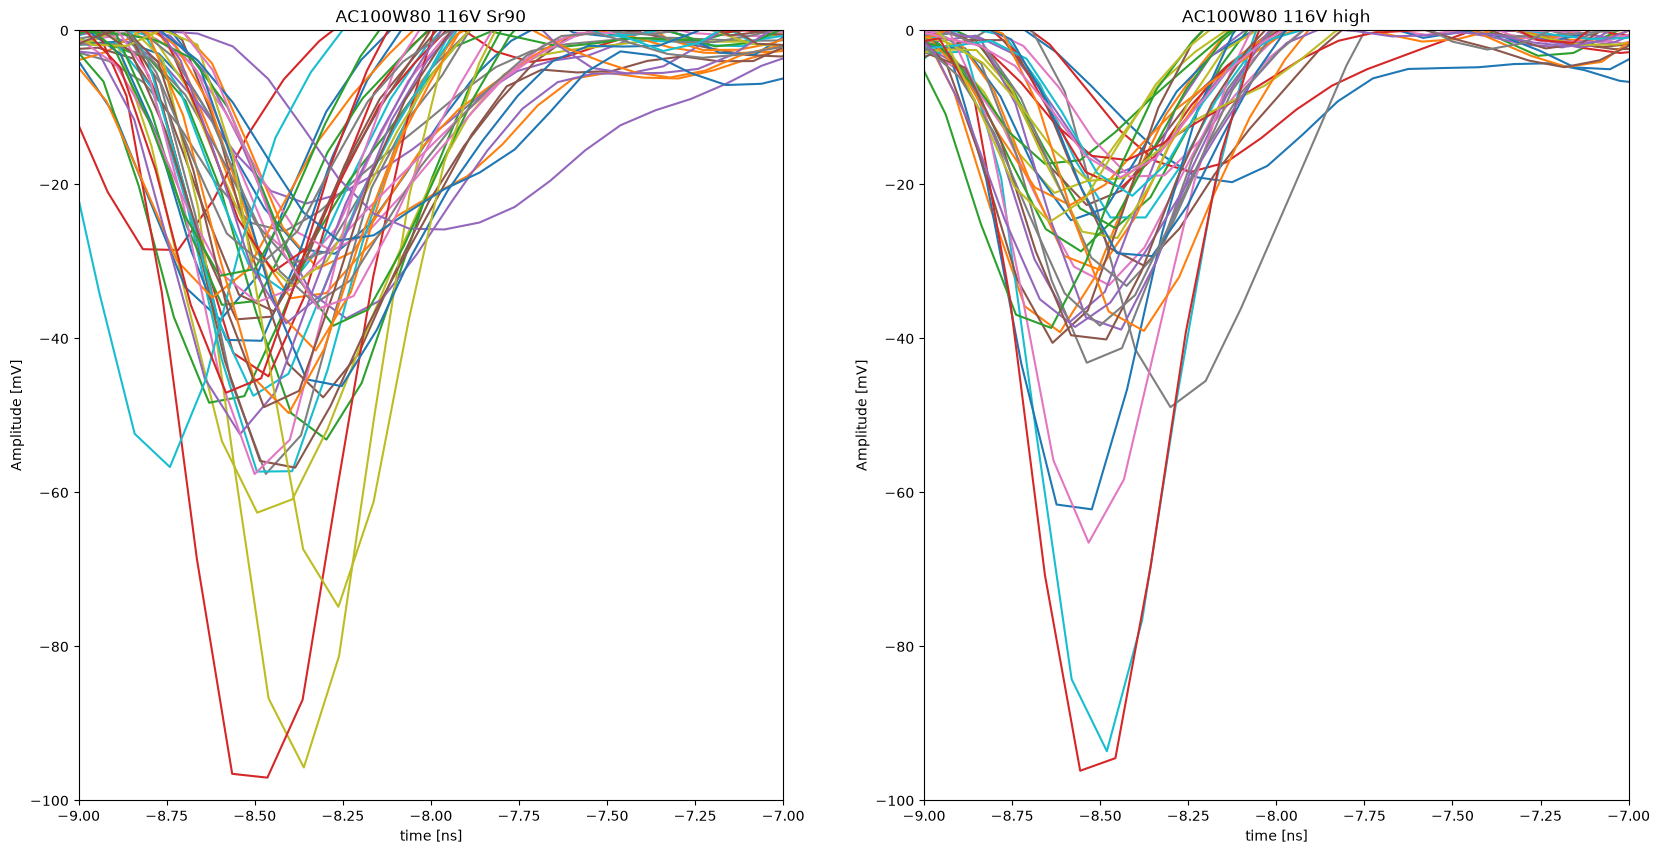

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


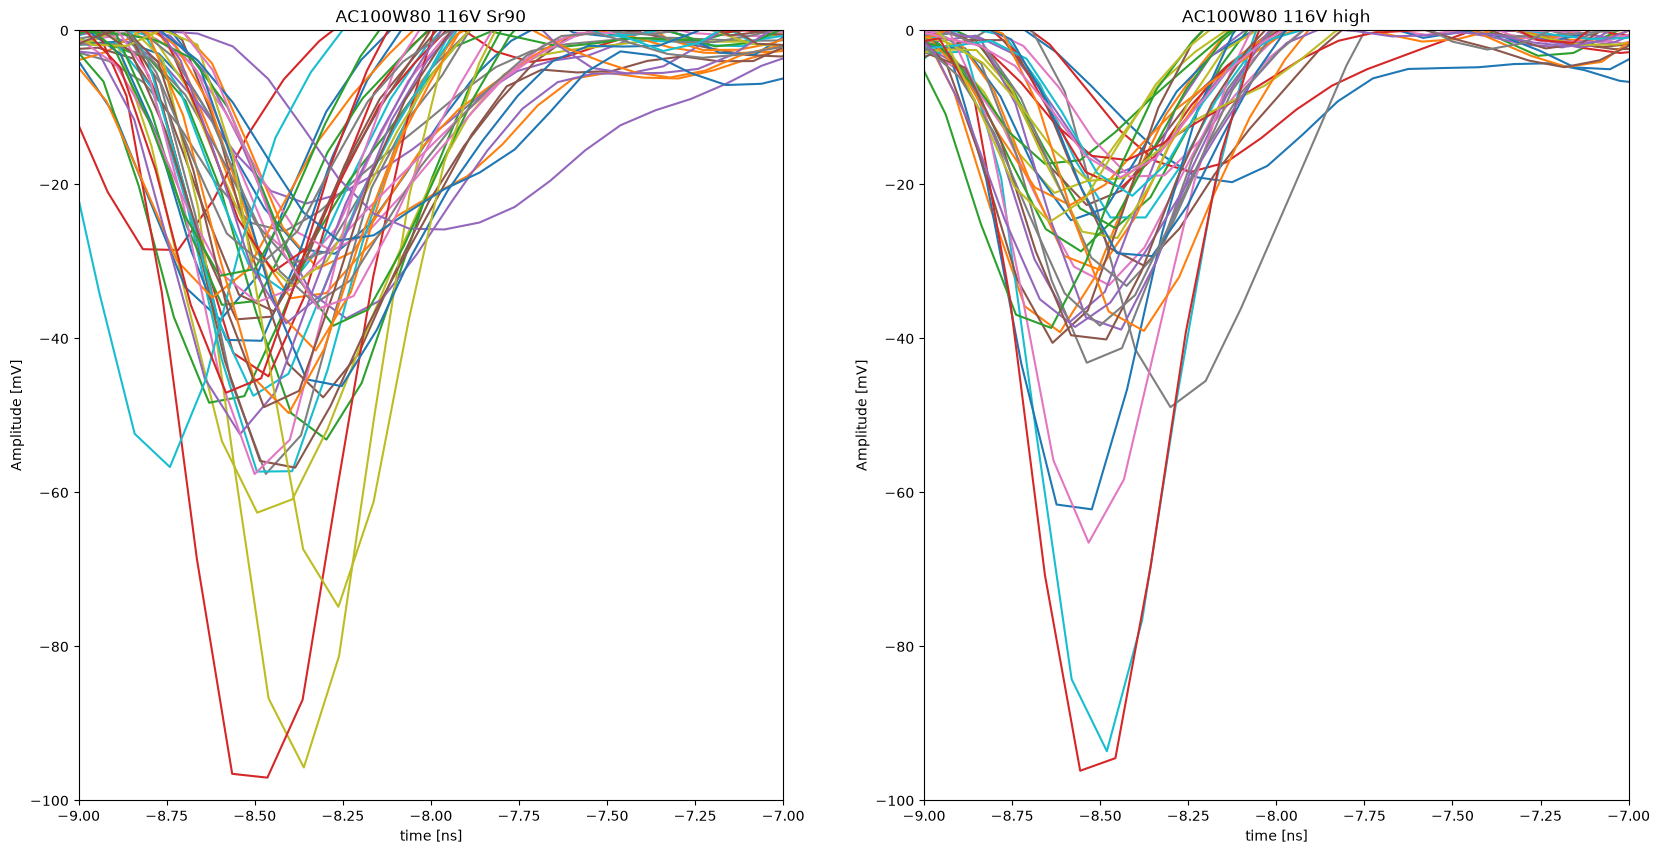

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


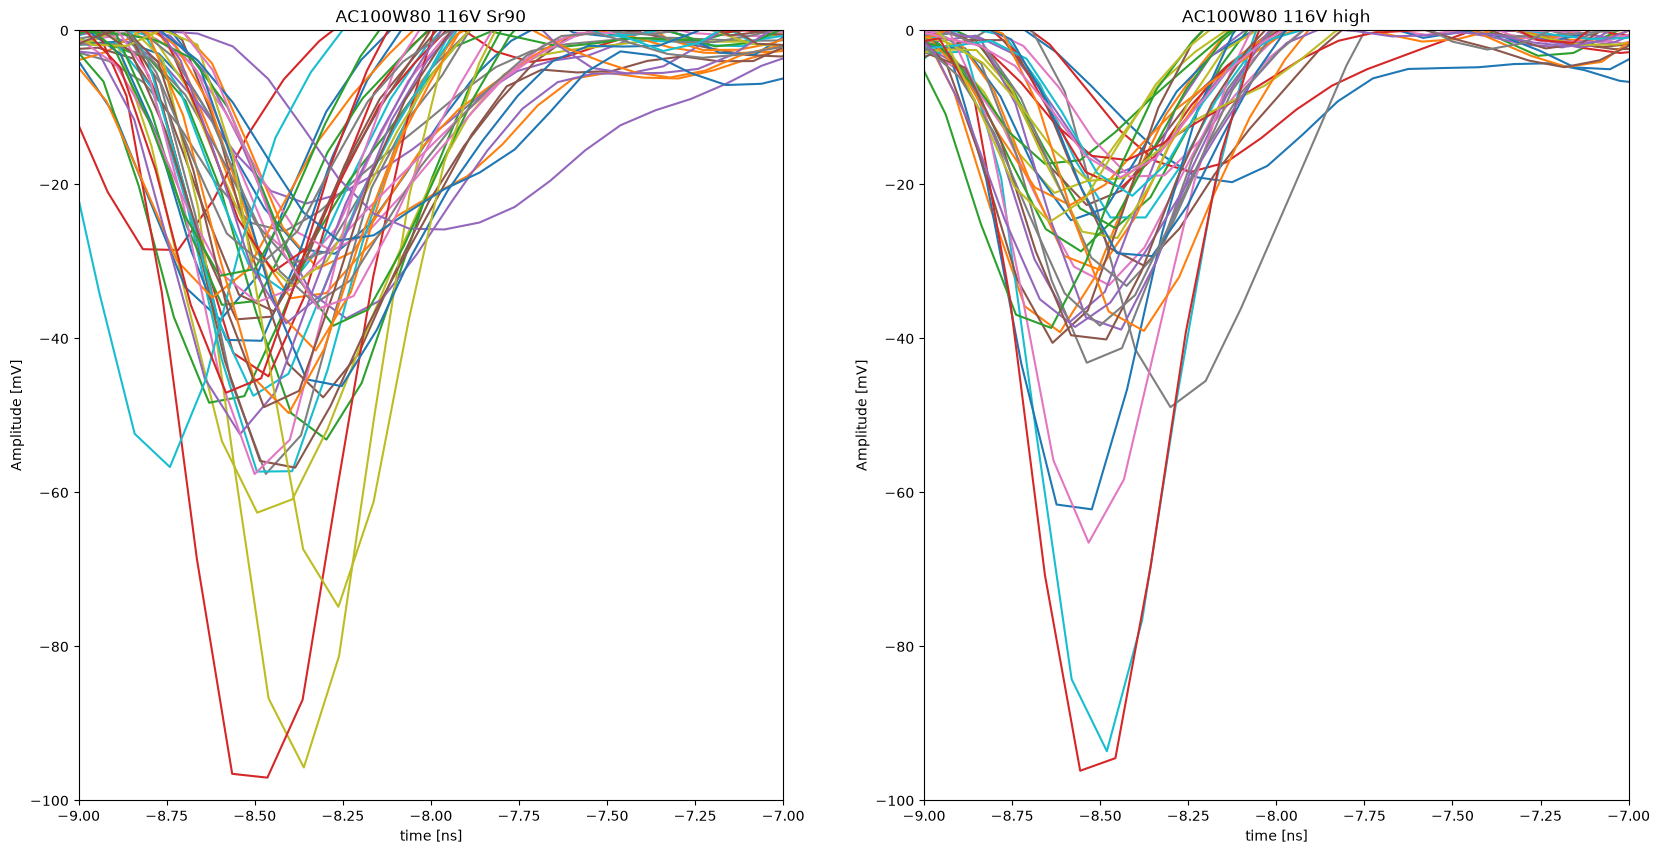

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


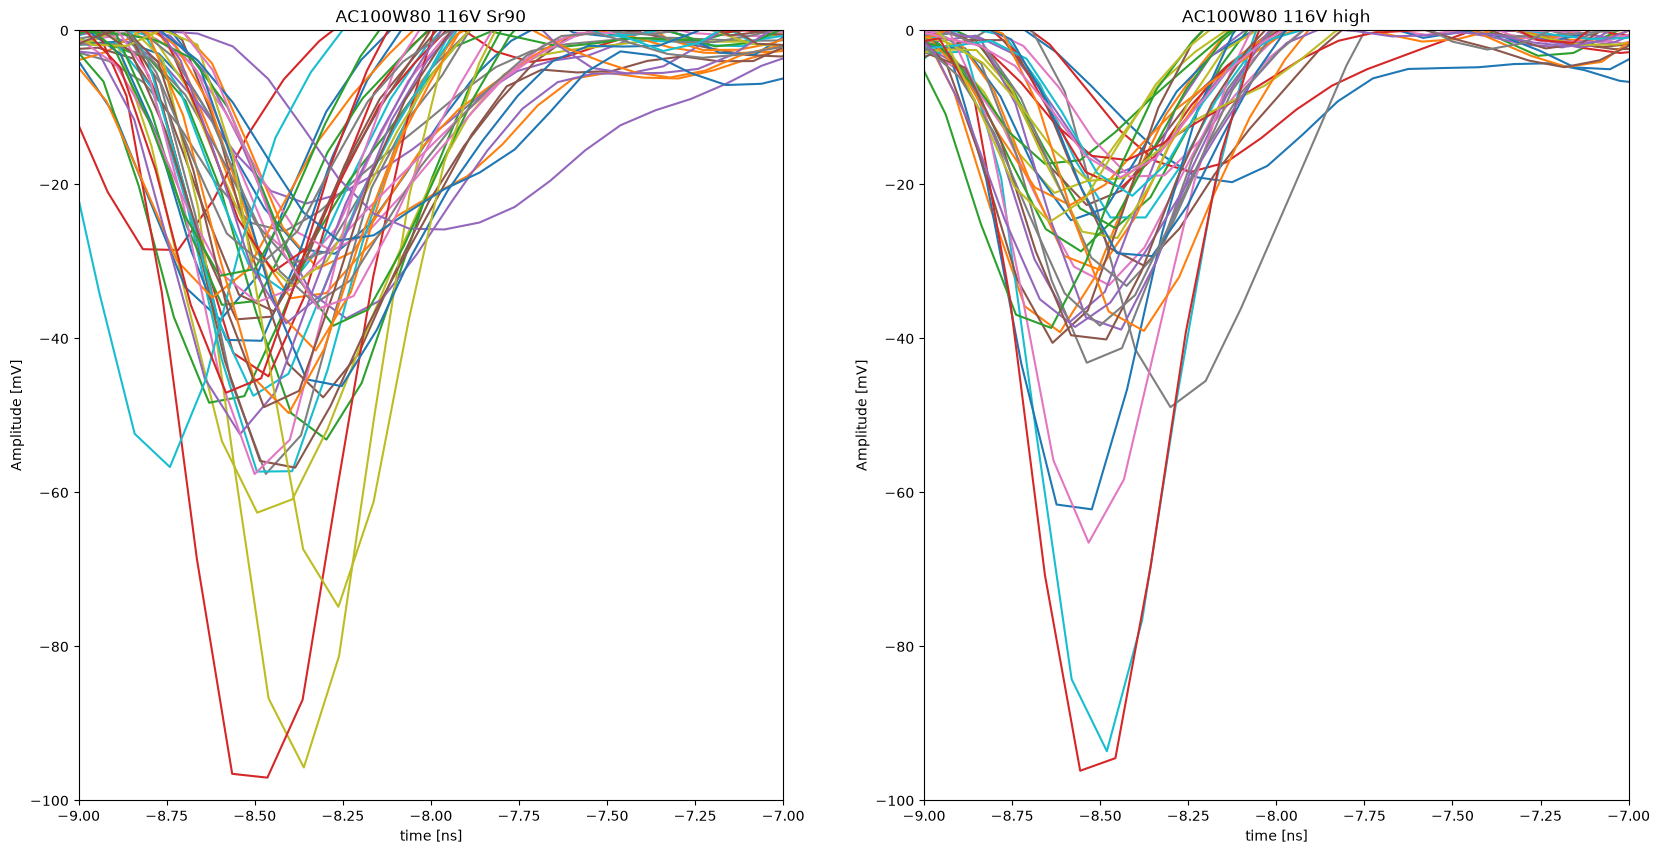

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


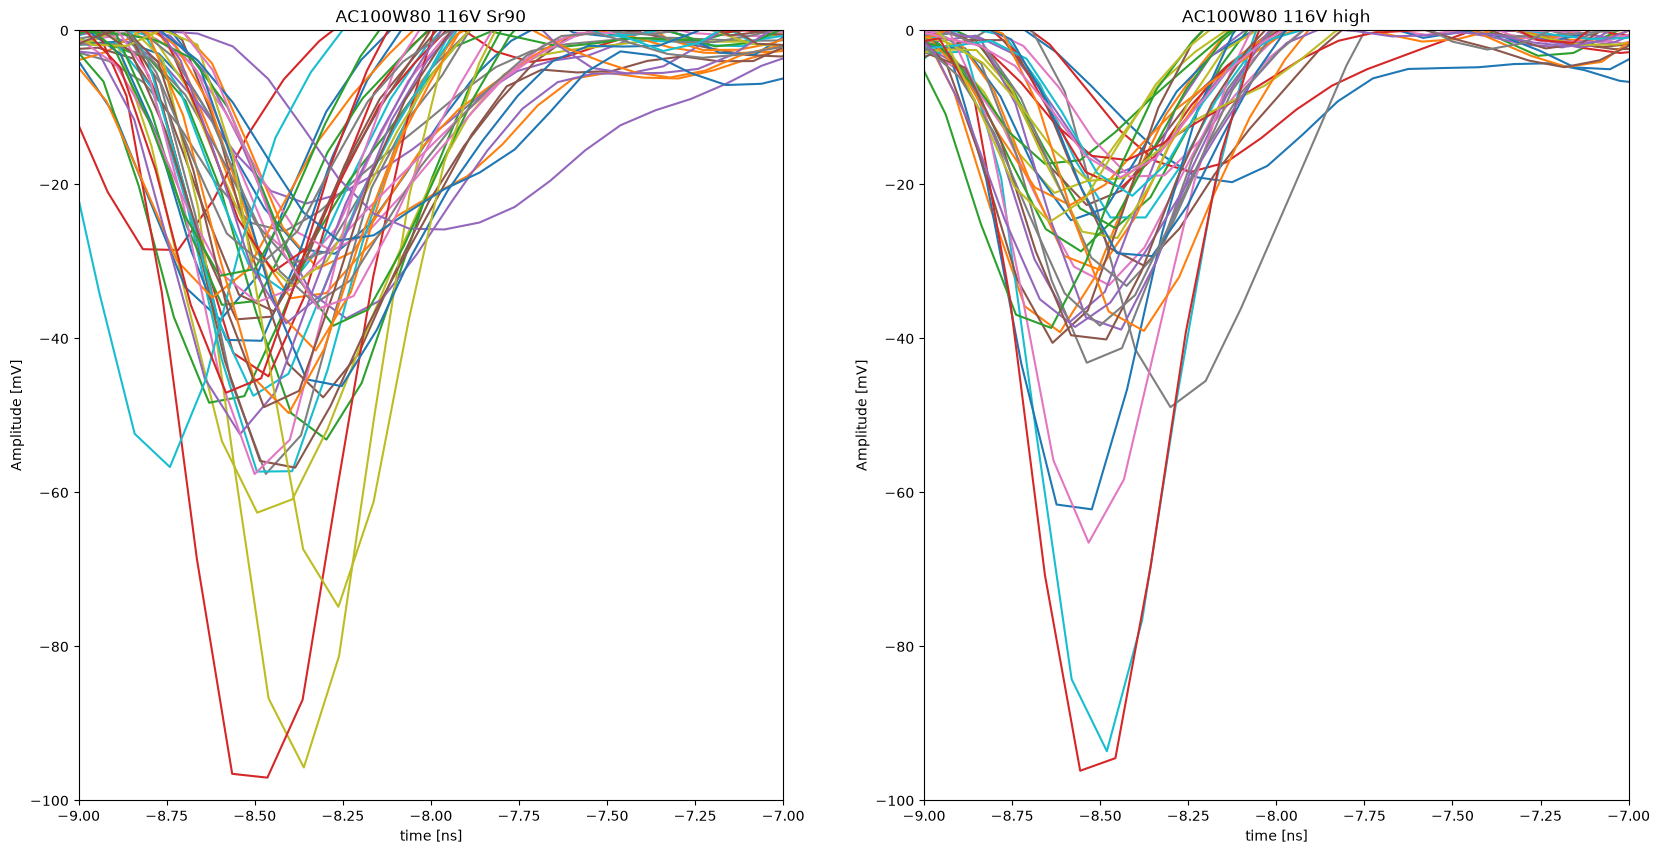

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


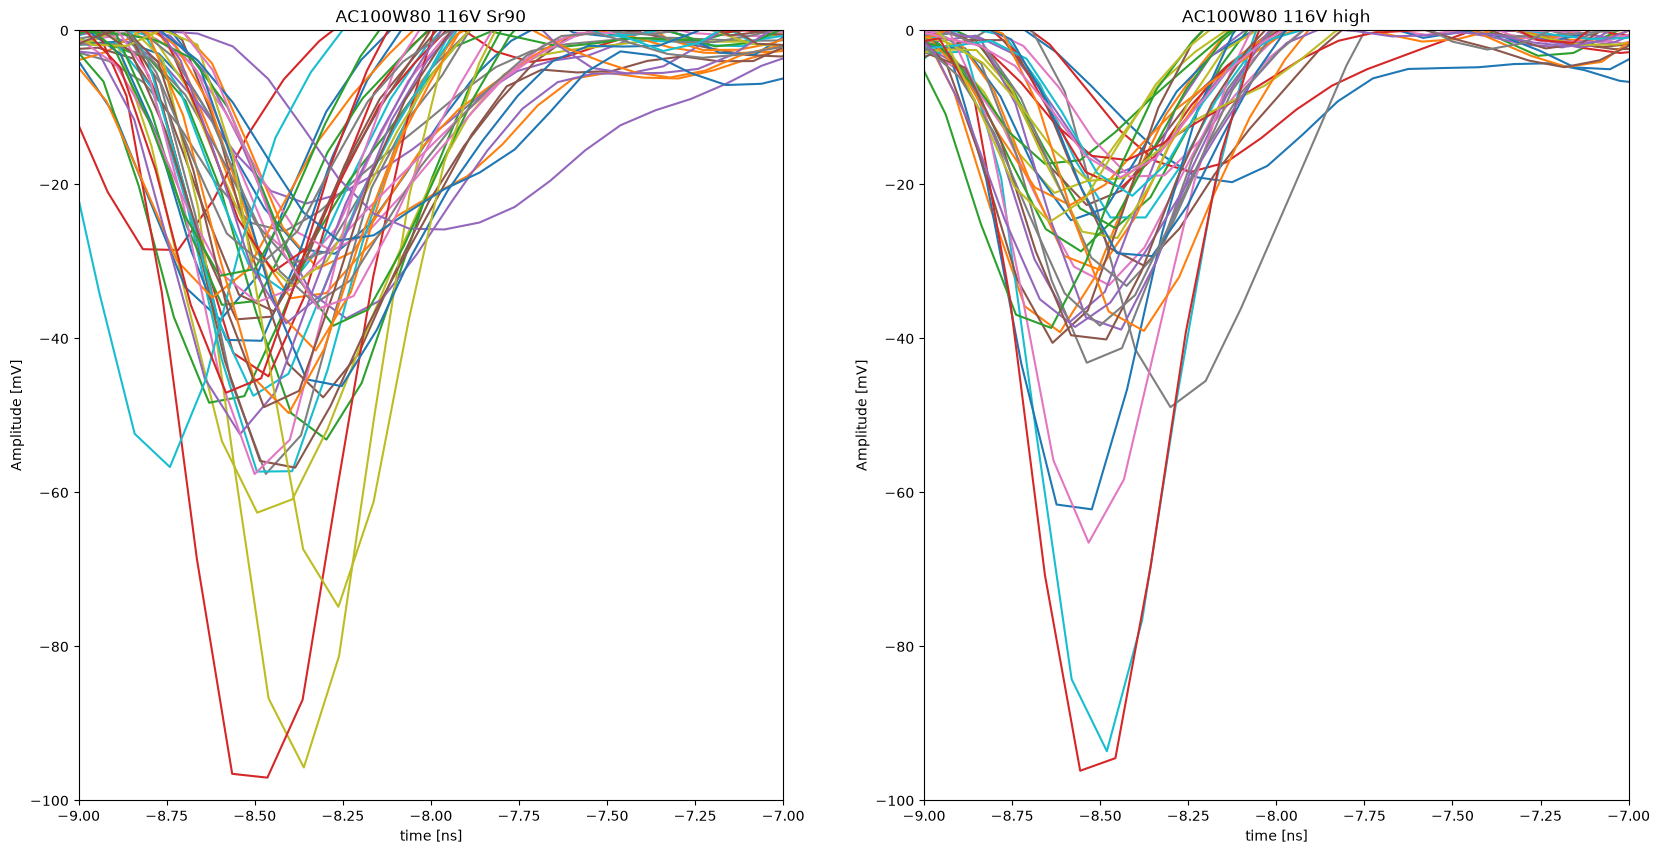

/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_.root
48
/Users/PITLab/3D_sensors/Processed_data/proc_F_AC100W80_strip3mm_bv116_mcp4400_trigCh4_Ch8_Sr90_high_threshold.root
39


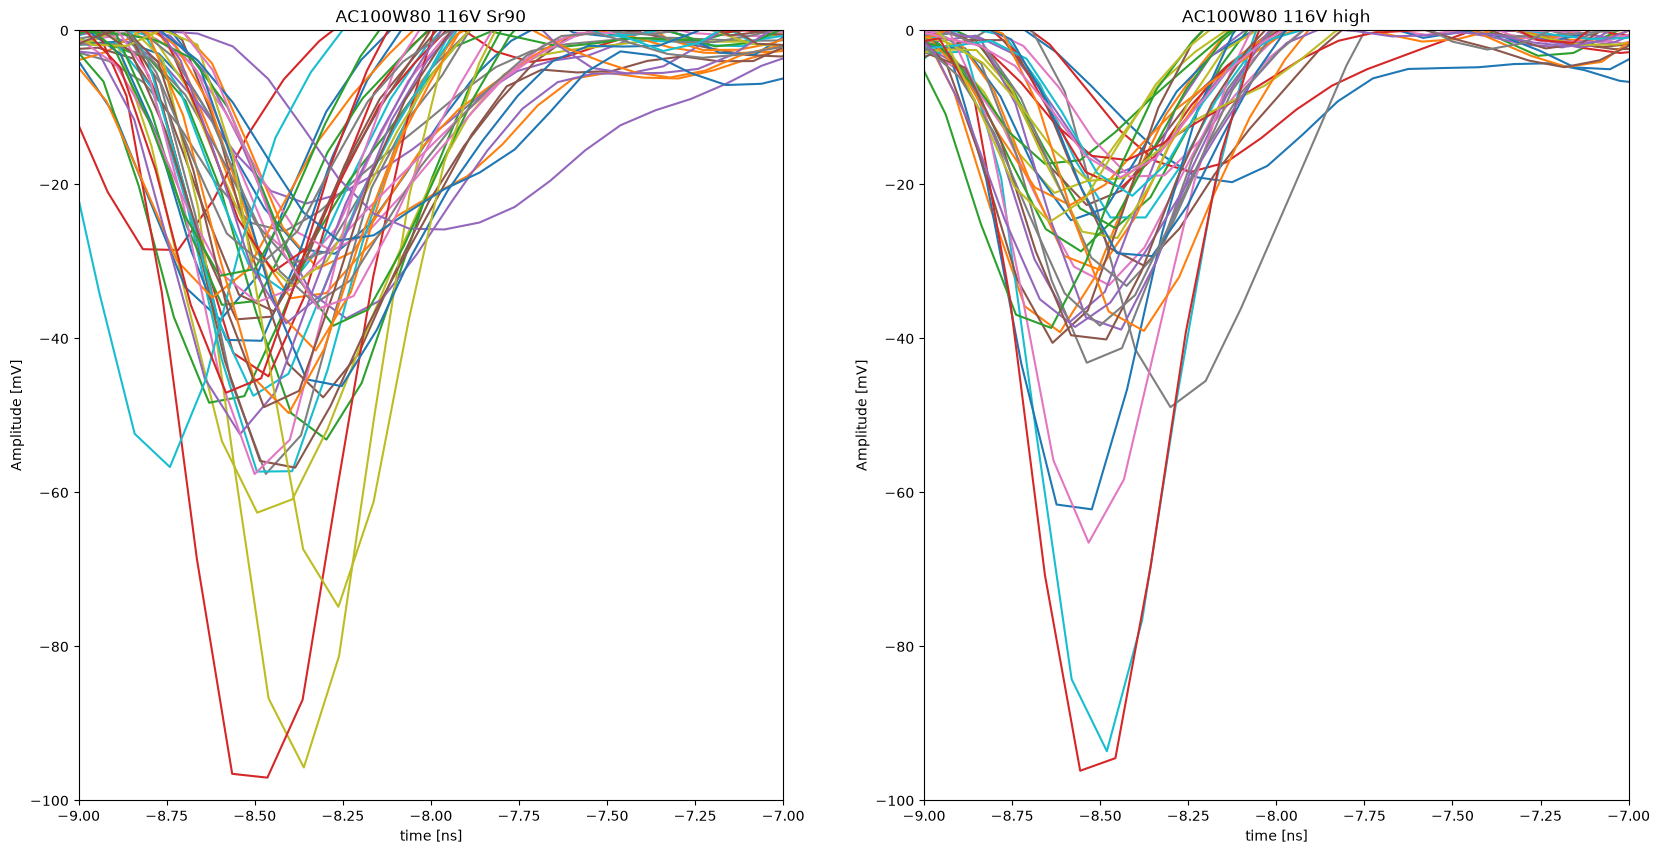

In [29]:
rows = 1
cols = len(filenames)
size = 10
for r in range(10):
    fig, ax = plt.subplots(rows, cols, figsize = (cols*size, rows*size))
    for f, file in enumerate(filenames):
        print(file)
        arrays = uproot.open(file)["pulse"].arrays()
        channels = arrays["channel"]
        time = arrays["time"]
        baseline_RMS = arrays["baseline_RMS"]
        amp = arrays["amp"]
        timestamps_10 = arrays["LP2_10"]
        timestamps_80 = arrays["LP2_80"]
        # for i, ch in enumerate(channels[0]):
        # y = (i) % cols
        # x = (i) // cols
        counter = 0
        for e in range(len(channels[r*100:(r+1)*100])):
            if baseline_RMS[e][3] > 3: continue
            if amp[e][3] / (amp[e][2] + amp[e][3] + amp[e][4]) < 0.5: continue
            if timestamps_10[e][3] < -13 or timestamps_10[e][3] < -13 or timestamps_10[e][3] > -1 or timestamps_10[e][3] > -1: continue
            # ax[f].plot(time[e][0], channels[e][7])
            ax[f].plot(time[e][0], channels[e][3])
            # if f != 3: ax[f].set_xlim(-12, -10)
            # else: ax[f].set_xlim(-9.5, -7)
            
            ax[f].set_xlim(-9, -7)
            ax[f].set_ylim(-100, 0)
    
            # if f != 3: ax[f].set_xlim(-8, -5.5)
            # else: ax[f].set_xlim(-5.0, -1.5)
            ax[f].set_title(legend_labels[f])
            ax[f].set_xlabel("time [ns]")
            ax[f].set_ylabel("Amplitude [mV]")
            counter+=1
        print(counter)
    plt.show()